### Import libraries

In [10]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import pandas as pd
import torch
import torch.nn as nn
import json
import os

from torchvision import transforms
from torchvision.models import efficientnet_b0

from dotenv import load_dotenv


### Load trained model

In [11]:
def find_project_root():
    current_path = Path.cwd().resolve()
    for path in [current_path, *current_path.parents]:

        if (
            (path / ".git").exists()
            or (
                (path / "data").is_dir()
                and (path / "models").is_dir()
            )
        ):
            return path

    raise FileNotFoundError(
        "Project root not found. "
        "Please run this notebook inside the project directory."
    )


ROOT = find_project_root()
MODEL_DIR = ROOT / "models"
MODEL_PATH = MODEL_DIR / "rice_disease_model.pth"

if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Trained model not found: {MODEL_PATH}"
    )

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)


class_to_idx = checkpoint["class_to_idx"]

idx_to_class = {
    index: name
    for name, index in class_to_idx.items()
}

num_classes = len(class_to_idx)

model = efficientnet_b0(weights=None)

in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    num_classes
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)


model = model.to(device)
model.eval()

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

### Select a new input image

In [12]:
BROWN_SPOT_DIR = ROOT / "data" / "raw" / "brown_spot"
BROWN_SPOT_IMAGES = sorted(BROWN_SPOT_DIR.glob("*.jpg"))
assert BROWN_SPOT_IMAGES, f"No brown spot images found in {BROWN_SPOT_DIR}"
NEW_IMAGE_PATH = BROWN_SPOT_IMAGES[0]

assert NEW_IMAGE_PATH.exists(), (
    f"Image not found: {NEW_IMAGE_PATH}"
)

print("Input image:", NEW_IMAGE_PATH)


Input image: D:\My_Project\Analyse\AI-Paddy-Farming-Intelligence\data\raw\brown_spot\brown_spot107.jpg


### Display uploaded image

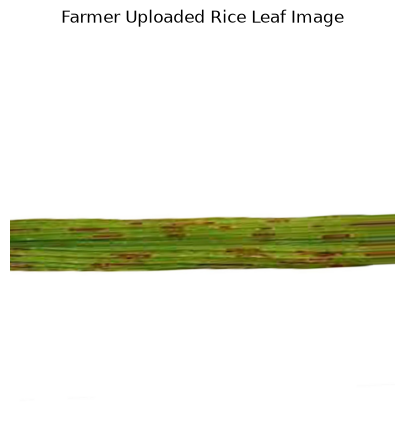

In [13]:
with Image.open(NEW_IMAGE_PATH) as image:
    input_image = image.convert("RGB")

plt.figure(figsize=(6, 5))
plt.imshow(input_image)
plt.title("Farmer Uploaded Rice Leaf Image")
plt.axis("off")
plt.show()


### Preprocess image

In [14]:
IMAGE_SIZE = checkpoint["image_size"]

prediction_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=checkpoint["mean"],
        std=checkpoint["std"]
    )
])

input_tensor = prediction_transform(
    input_image
).unsqueeze(0).to(device)

### Predict disease category

In [ ]:
with torch.no_grad():

    outputs = model(input_tensor)

    probabilities = torch.softmax(
        outputs,
        dim=1
    )

    top_probabilities, top_indices = torch.topk(
        probabilities,
        k=min(3, num_classes),
        dim=1
    )

predicted_index = top_indices[0][0].item()

predicted_disease = idx_to_class[predicted_index]

model_score = top_probabilities[0][0].item()

print("PREDICTION RESULT")

print("Predicted Disease:", predicted_disease)

print(f"Model Score: {model_score * 100:.2f}%")

print("\nTop 3 Predictions:")

for probability, index in zip(
    top_probabilities[0],
    top_indices[0]
):

    disease = idx_to_class[index.item()]

    print(
        f"{disease}: {probability.item() * 100:.2f}%"
    )

PREDICTION RESULT
Predicted Disease: brown_spot
Model Score: 99.88%

Top 3 Predictions:
brown_spot: 99.88%
leaf_blast: 0.11%
Healthy: 0.01%
